
Search Query: Python machine learning data

Ranked Search Results:
  Document  Relevance  PageRank  Final Score
1     Doc1     0.5772    0.2489       0.4787
2     Doc2     0.4922    0.3365       0.4455
3     Doc5     0.3431    0.1485       0.2848
4     Doc3     0.1229    0.0300       0.0951
5     Doc4     0.0000    0.2361       0.0708


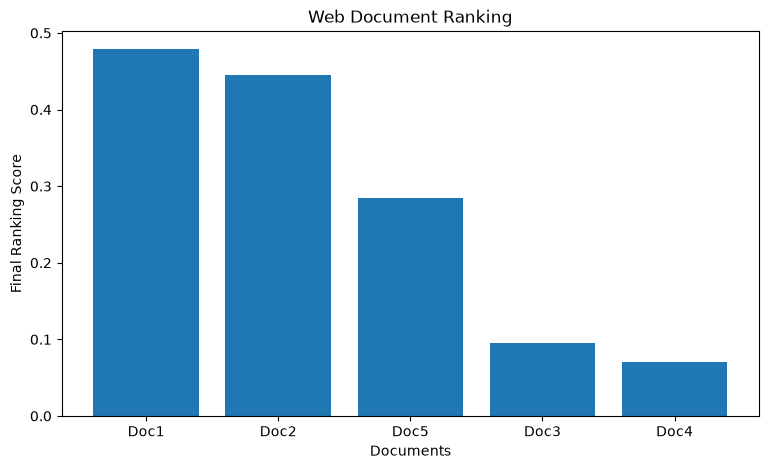

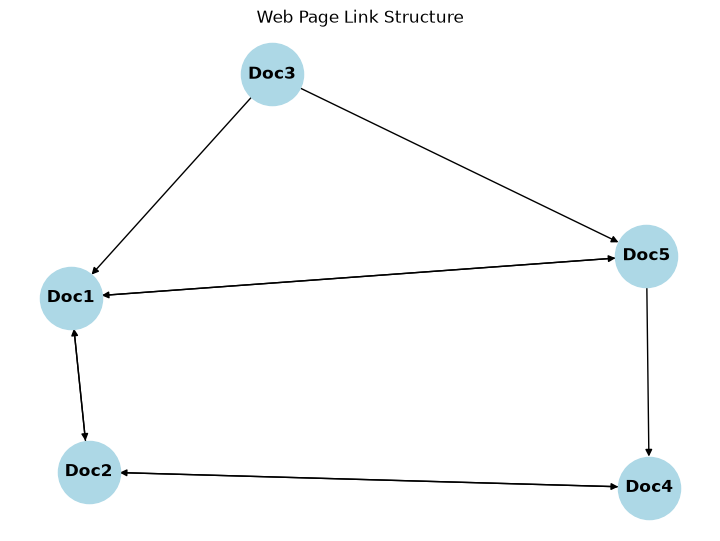


Document Ranking Completed Successfully!


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Create a Small Web Document Dataset
documents = {
    "Doc1": "Python programming is used in machine learning and data science",
    "Doc2": "Machine learning helps computers learn from data",
    "Doc3": "Python is a popular programming language for web development",
    "Doc4": "Search engines rank web pages based on relevance and importance",
    "Doc5": "Data science uses Python for data analysis and visualization"
}

# 2. User Search Query
query = "Python machine learning data"

# 3. Calculate TF-IDF
vectorizer = TfidfVectorizer()

doc_vectors = vectorizer.fit_transform(documents.values())
query_vector = vectorizer.transform([query])

# 4. Calculate Relevance using Cosine Similarity
similarity = cosine_similarity(
    query_vector, doc_vectors
).flatten()

# 5. Create Web Page Link Graph
G = nx.DiGraph()

G.add_edges_from([
    ("Doc1", "Doc2"),
    ("Doc1", "Doc5"),
    ("Doc2", "Doc1"),
    ("Doc2", "Doc4"),
    ("Doc3", "Doc1"),
    ("Doc3", "Doc5"),
    ("Doc4", "Doc2"),
    ("Doc5", "Doc1"),
    ("Doc5", "Doc4")
])

# 6. Calculate PageRank
pagerank = nx.pagerank(G, alpha=0.85)

# 7. Combine Relevance and Importance
results = pd.DataFrame({
    "Document": list(documents.keys()),
    "Relevance": similarity,
    "PageRank": [pagerank[doc] for doc in documents]
})

results["Final Score"] = (
    0.7 * results["Relevance"] +
    0.3 * results["PageRank"]
)

# 8. Rank Documents
results = results.sort_values(
    by="Final Score", ascending=False
).reset_index(drop=True)

results.index += 1

print("\nSearch Query:", query)
print("\nRanked Search Results:")
print(results.round(4))

# 9. Visualize Ranking
plt.figure(figsize=(9, 5))

plt.bar(
    results["Document"],
    results["Final Score"]
)

plt.title("Web Document Ranking")
plt.xlabel("Documents")
plt.ylabel("Final Ranking Score")
plt.show()

# 10. Visualize Web Link Graph
plt.figure(figsize=(7, 5))

nx.draw(
    G,
    with_labels=True,
    node_color="lightblue",
    node_size=2000,
    arrows=True,
    font_weight="bold"
)

plt.title("Web Page Link Structure")
plt.show()

print("\nDocument Ranking Completed Successfully!")